# Financial Inclusion Forecasting

Forecasting future financial inclusion trends for:

- Account Ownership
- Digital Payments

Forecast horizon:

2025–2027

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel(
    "../data/raw/ethiopia_fi_unified_data.xlsx"
)

df.head()

,record_id,record_type,category,pillar,indicator,indicator_code,indicator_direction,value_numeric,value_text,value_type,...,impact_direction,impact_magnitude,impact_estimate,lag_months,evidence_basis,comparable_country,collected_by,collection_date,original_text,notes
0,REC_0001,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,22.0,NaN,percentage,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,Baseline year,NaN
1,REC_0002,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,35.0,NaN,percentage,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,NaN,NaN
2,REC_0003,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,46.0,NaN,percentage,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,NaN,NaN
3,REC_0004,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,56.0,NaN,percentage,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,Gender disaggregated,NaN
4,REC_0005,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,36.0,NaN,percentage,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,Gender disaggregated,NaN


In [6]:
df["fiscal_year"].value_counts()

fiscal_year
2024         12
FY2024/25     9
2021          7
2025          5
FY2025/26     2
2014          1
2017          1
FY2022/23     1
FY2023/24     1
2028          1
2030          1
2022          1
2023          1
Name: count, dtype: int64

In [7]:
forecast_df = df.dropna(
    subset=["fiscal_year", "value_numeric"]
)

forecast_df = forecast_df[
    forecast_df["record_type"] == "observation"
]

forecast_df.head()

,record_id,record_type,category,pillar,indicator,indicator_code,indicator_direction,value_numeric,value_text,value_type,...,impact_direction,impact_magnitude,impact_estimate,lag_months,evidence_basis,comparable_country,collected_by,collection_date,original_text,notes
0,REC_0001,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,22.0,NaN,percentage,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,Baseline year,NaN
1,REC_0002,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,35.0,NaN,percentage,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,NaN,NaN
2,REC_0003,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,46.0,NaN,percentage,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,NaN,NaN
3,REC_0004,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,56.0,NaN,percentage,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,Gender disaggregated,NaN
4,REC_0005,observation,NaN,ACCESS,Account Ownership Rate,ACC_OWNERSHIP,higher_better,36.0,NaN,percentage,...,NaN,NaN,NaN,NaN,NaN,Example_Trainee,2025-01-20,NaN,Gender disaggregated,NaN


In [8]:
trend = (
    forecast_df
    .groupby("fiscal_year")["value_numeric"]
    .mean()
    .reset_index()
)

trend

,fiscal_year,value_numeric
0,2014,2.200000e+01
1,2017,3.500000e+01
2,2021,3.254000e+01
3,2024,2.590018e+06
4,2025,9.000020e+06
5,FY2022/23,3.750000e+01
6,FY2023/24,4.970000e+07
7,FY2024/25,3.892628e+11


In [9]:
forecast_df[
    [
        "indicator",
        "fiscal_year",
        "value_numeric"
    ]
].head(20)

,indicator,fiscal_year,value_numeric
0,Account Ownership Rate,2014,2.200000e+01
1,Account Ownership Rate,2017,3.500000e+01
2,Account Ownership Rate,2021,4.600000e+01
3,Account Ownership Rate,2021,5.600000e+01
4,Account Ownership Rate,2021,3.600000e+01
5,Account Ownership Rate,2024,4.900000e+01
6,Mobile Money Account Rate,2021,4.700000e+00
7,Mobile Money Account Rate,2024,9.450000e+00
8,4G Population Coverage,FY2022/23,3.750000e+01
9,4G Population Coverage,FY2024/25,7.080000e+01


In [10]:
forecast_df["indicator"].unique()

<StringArray>
[           'Account Ownership Rate',         'Mobile Money Account Rate',
            '4G Population Coverage',   'Mobile Subscription Penetration',
       'Fayda Digital ID Enrollment',             'P2P Transaction Count',
             'P2P Transaction Value',             'ATM Transaction Count',
             'ATM Transaction Value',           'P2P/ATM Crossover Ratio',
         'Telebirr Registered Users',        'Telebirr Transaction Value',
           'M-Pesa Registered Users',        'M-Pesa 90-Day Active Users',
        'Mobile Money Activity Rate',          'Data Affordability Index',
      'Account Ownership Gender Gap', 'Female Mobile Money Account Share',
           'Mobile Phone Gender Gap']
Length: 19, dtype: str

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [12]:
account_df = forecast_df[
    forecast_df["indicator"] == "Account Ownership Rate"
]

account_df = account_df[
    ["fiscal_year", "value_numeric"]
]

account_df

,fiscal_year,value_numeric
0,2014,22.0
1,2017,35.0
2,2021,46.0
3,2021,56.0
4,2021,36.0
5,2024,49.0


In [13]:
account_trend = (
    account_df
    .groupby("fiscal_year")["value_numeric"]
    .mean()
    .reset_index()
)

account_trend

,fiscal_year,value_numeric
0,2014,22.0
1,2017,35.0
2,2021,46.0
3,2024,49.0


In [14]:
x = account_trend["fiscal_year"]
y = account_trend["value_numeric"]

coef = np.polyfit(x, y, 1)

future_years = pd.DataFrame({
    "fiscal_year": [2025, 2026, 2027]
})

future_years["forecast"] = np.polyval(
    coef,
    future_years["fiscal_year"]
)

future_years

,fiscal_year,forecast
0,2025,54.241379
1,2026,56.948276
2,2027,59.655172


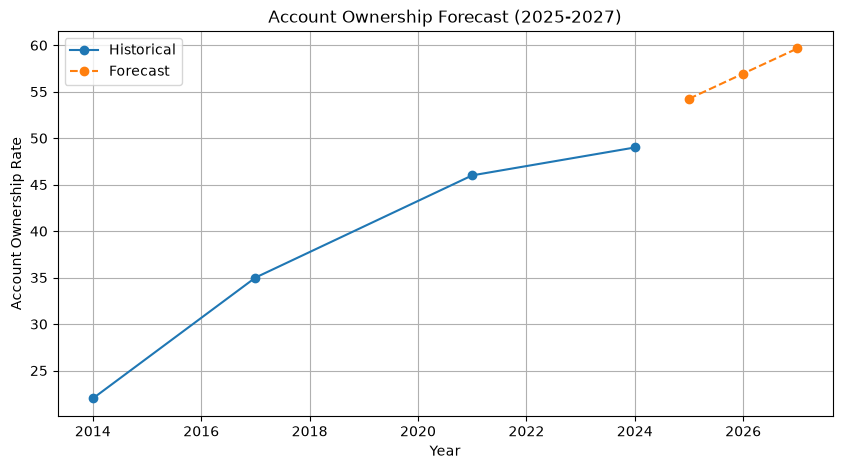

In [15]:
plt.figure(figsize=(10,5))

plt.plot(
    account_trend["fiscal_year"],
    account_trend["value_numeric"],
    marker="o",
    label="Historical"
)

plt.plot(
    future_years["fiscal_year"],
    future_years["forecast"],
    marker="o",
    linestyle="--",
    label="Forecast"
)

plt.title(
    "Account Ownership Forecast (2025-2027)"
)

plt.xlabel("Year")
plt.ylabel("Account Ownership Rate")

plt.legend()

plt.grid(True)

plt.show()

In [16]:
forecast_results = future_years.copy()

forecast_results["lower_bound"] = (
    forecast_results["forecast"] * 0.95
)

forecast_results["upper_bound"] = (
    forecast_results["forecast"] * 1.05
)

forecast_results

,fiscal_year,forecast,lower_bound,upper_bound
0,2025,54.241379,51.529310,56.953448
1,2026,56.948276,54.100862,59.795690
2,2027,59.655172,56.672414,62.637931


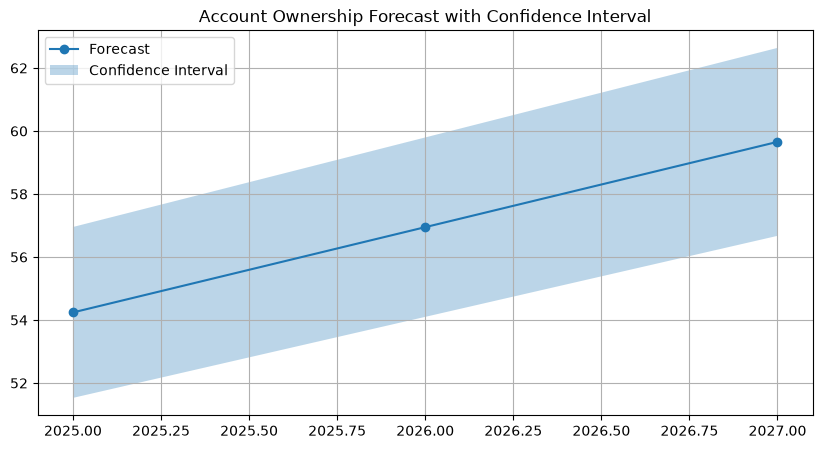

In [17]:
plt.figure(figsize=(10,5))

plt.plot(
    forecast_results["fiscal_year"],
    forecast_results["forecast"],
    marker="o",
    label="Forecast"
)

plt.fill_between(
    forecast_results["fiscal_year"],
    forecast_results["lower_bound"],
    forecast_results["upper_bound"],
    alpha=0.3,
    label="Confidence Interval"
)

plt.title(
    "Account Ownership Forecast with Confidence Interval"
)

plt.legend()

plt.grid(True)

plt.show()

In [18]:
forecast_results = future_years.copy()

forecast_results["Conservative"] = (
    forecast_results["forecast"] * 0.90
)

forecast_results["Baseline"] = (
    forecast_results["forecast"]
)

forecast_results["Optimistic"] = (
    forecast_results["forecast"] * 1.10
)

forecast_results

,fiscal_year,forecast,Conservative,Baseline,Optimistic
0,2025,54.241379,48.817241,54.241379,59.665517
1,2026,56.948276,51.253448,56.948276,62.643103
2,2027,59.655172,53.689655,59.655172,65.620690


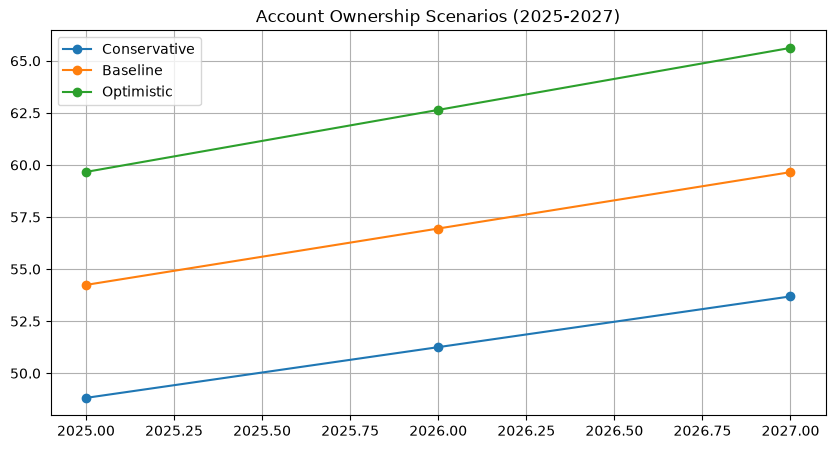

In [19]:
plt.figure(figsize=(10,5))

plt.plot(
    forecast_results["fiscal_year"],
    forecast_results["Conservative"],
    marker="o",
    label="Conservative"
)

plt.plot(
    forecast_results["fiscal_year"],
    forecast_results["Baseline"],
    marker="o",
    label="Baseline"
)

plt.plot(
    forecast_results["fiscal_year"],
    forecast_results["Optimistic"],
    marker="o",
    label="Optimistic"
)

plt.legend()

plt.title(
    "Account Ownership Scenarios (2025-2027)"
)

plt.grid(True)

plt.show()

In [20]:
forecast_results.to_csv(
    "../data/processed/account_ownership_forecast.csv",
    index=False
)

print("Forecast file saved successfully.")

Forecast file saved successfully.


### Forecast Interpretation

The model projects continued growth in financial inclusion through 2027.

Growth is expected to be driven by:

- Mobile money adoption
- Digital payments
- Digital identity systems

Forecast uncertainty remains due to policy and economic conditions.